# 02 — Classical baselines

**Q1. What simple classical ML approaches work as a first baseline?**

Three baselines, all on the session-grouped split v2 (`data/splits/`):

| Model | Features | Dims |
|---|---|---|
| Majority class | none: always predict *Negative* | – |
| KNN | raw pixels: image downsampled to 32×32, flattened, standardised, PCA to 100 | 100 |
| KNN | HSV colour histograms: 32 bins per channel, each L1-normalised | 96 |

For each KNN, `k` ∈ {1, 3, 5, 7, 11, 15, 21, 31} and the weighting (uniform or by distance) are chosen on **validation** macro F1. The test set is scored once, with the chosen settings.

This notebook reads the saved results. To re-run the models:

```bash
python -m src.train --config experiments/configs/knn_pixels.yaml
python -m src.train --config experiments/configs/knn_hist.yaml
```

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import Image, display

ROOT = Path('..')
METRICS = ROOT / 'results' / 'metrics'
CM_DIR = ROOT / 'results' / 'confusion_matrices'
FIG_DIR = ROOT / 'results' / 'figures'
sns.set_theme(style='whitegrid')

KEYS = ['macro_f1', 'macro_precision', 'macro_recall', 'accuracy']


def load(run):
    return json.loads((METRICS / f'{run}.json').read_text())


def scores(runs, who='model'):
    """One row per run: val and test metrics from the saved results JSON."""
    rows = {}
    for name, r in runs.items():
        rows[name] = {f'{split} {k}': r['splits'][split][who][k]
                      for split in ('val', 'test') for k in KEYS}
    return pd.DataFrame(rows).T.round(3)


def per_class_f1(runs, split='test'):
    return pd.DataFrame({name: {c: m['f1'] for c, m in r['splits'][split]['model']['per_class'].items()}
                         for name, r in runs.items()}).round(3)

In [2]:
runs = {'KNN pixels': load('knn_pixels'), 'KNN colour histogram': load('knn_hist')}
majority = scores({'Majority class': runs['KNN colour histogram']}, who='majority_baseline')
table = pd.concat([majority, scores(runs)])
table['best k / weights'] = ['–'] + [f"{r['best_params']['n_neighbors']} / {r['best_params']['weights']}"
                                     for r in runs.values()]
table

,val macro_f1,val macro_precision,val macro_recall,val accuracy,test macro_f1,test macro_precision,test macro_recall,test accuracy,best k / weights
Majority class,0.076,0.058,0.111,0.524,0.076,0.058,0.111,0.525,–
KNN pixels,0.175,0.214,0.186,0.400,0.180,0.218,0.192,0.441,3 / uniform
KNN colour histogram,0.406,0.442,0.394,0.524,0.452,0.493,0.437,0.581,11 / distance


## 1. Choosing k on validation

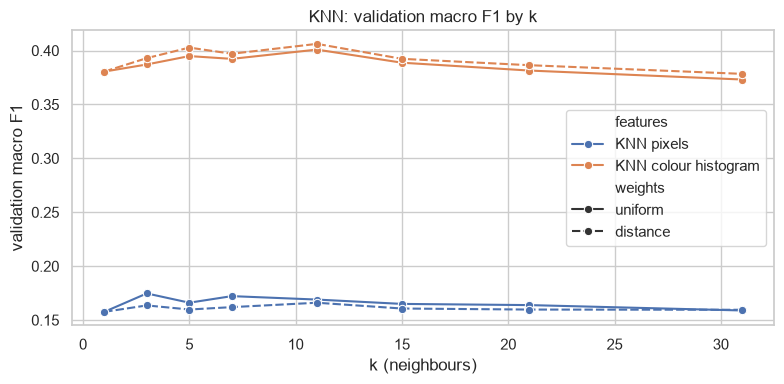

In [3]:
search = pd.concat([pd.DataFrame(r['search']).assign(features=name) for name, r in runs.items()])
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=search, x='n_neighbors', y='val_macro_f1', hue='features', style='weights', marker='o', ax=ax)
ax.set_xlabel('k (neighbours)'); ax.set_ylabel('validation macro F1')
ax.set_title('KNN: validation macro F1 by k')
fig.tight_layout(); fig.savefig(FIG_DIR / 'baseline_k_search.png', dpi=150)

## 2. Per-class test F1

,KNN pixels,KNN colour histogram
Chinee apple,0.171,0.228
Lantana,0.089,0.517
Parkinsonia,0.190,0.525
Parthenium,0.092,0.211
Prickly acacia,0.134,0.614
Rubber vine,0.018,0.344
Siam weed,0.149,0.588
Snake weed,0.097,0.319
Negative,0.682,0.726


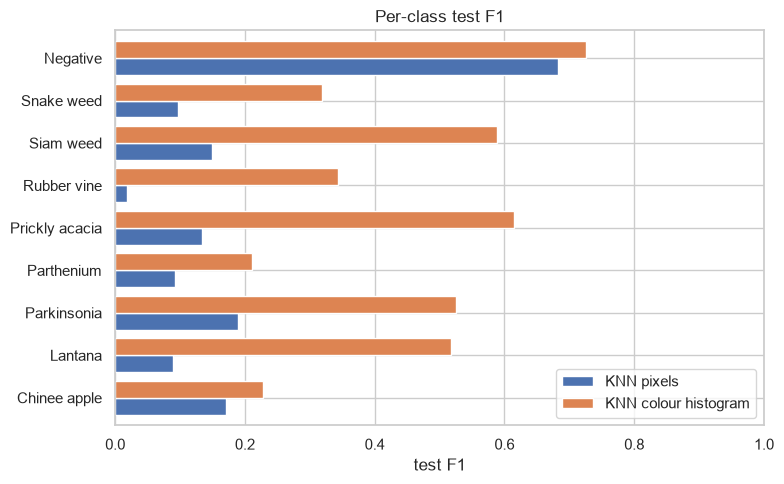

In [4]:
f1 = per_class_f1(runs)
ax = f1.plot.barh(figsize=(8, 5), width=0.8)
ax.set_xlabel('test F1'); ax.set_xlim(0, 1); ax.set_title('Per-class test F1')
ax.figure.tight_layout(); ax.figure.savefig(FIG_DIR / 'baseline_per_class_f1.png', dpi=150)
f1

## 3. Confusion matrices (test, row-normalised)

Rows are the true class, so the diagonal is each class's recall.

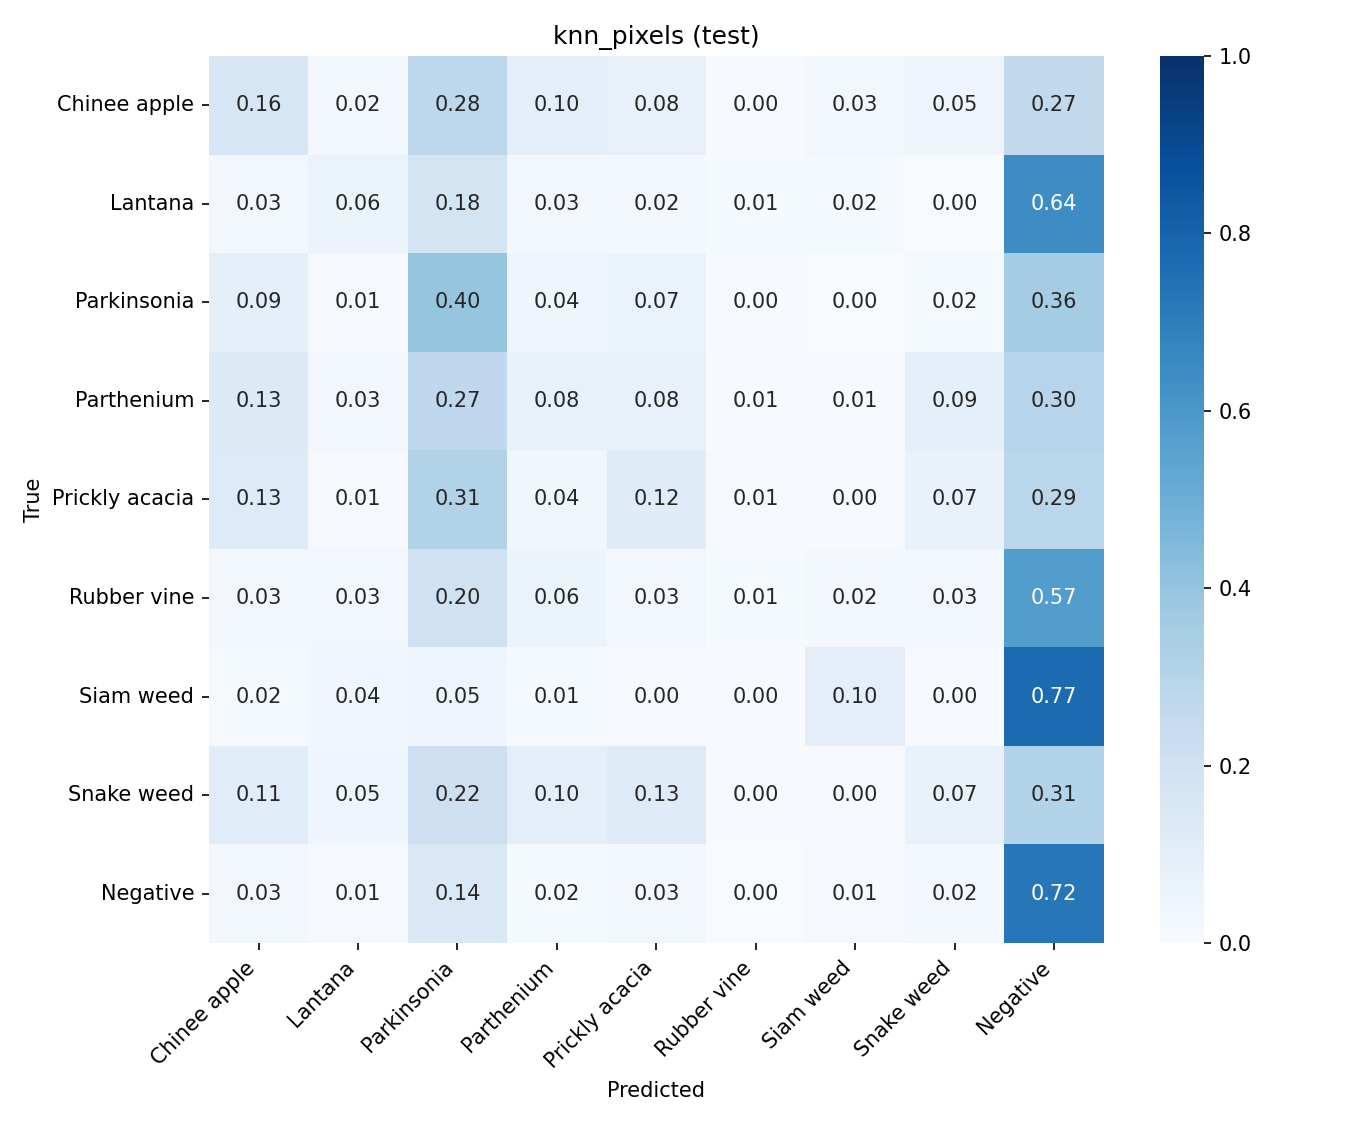

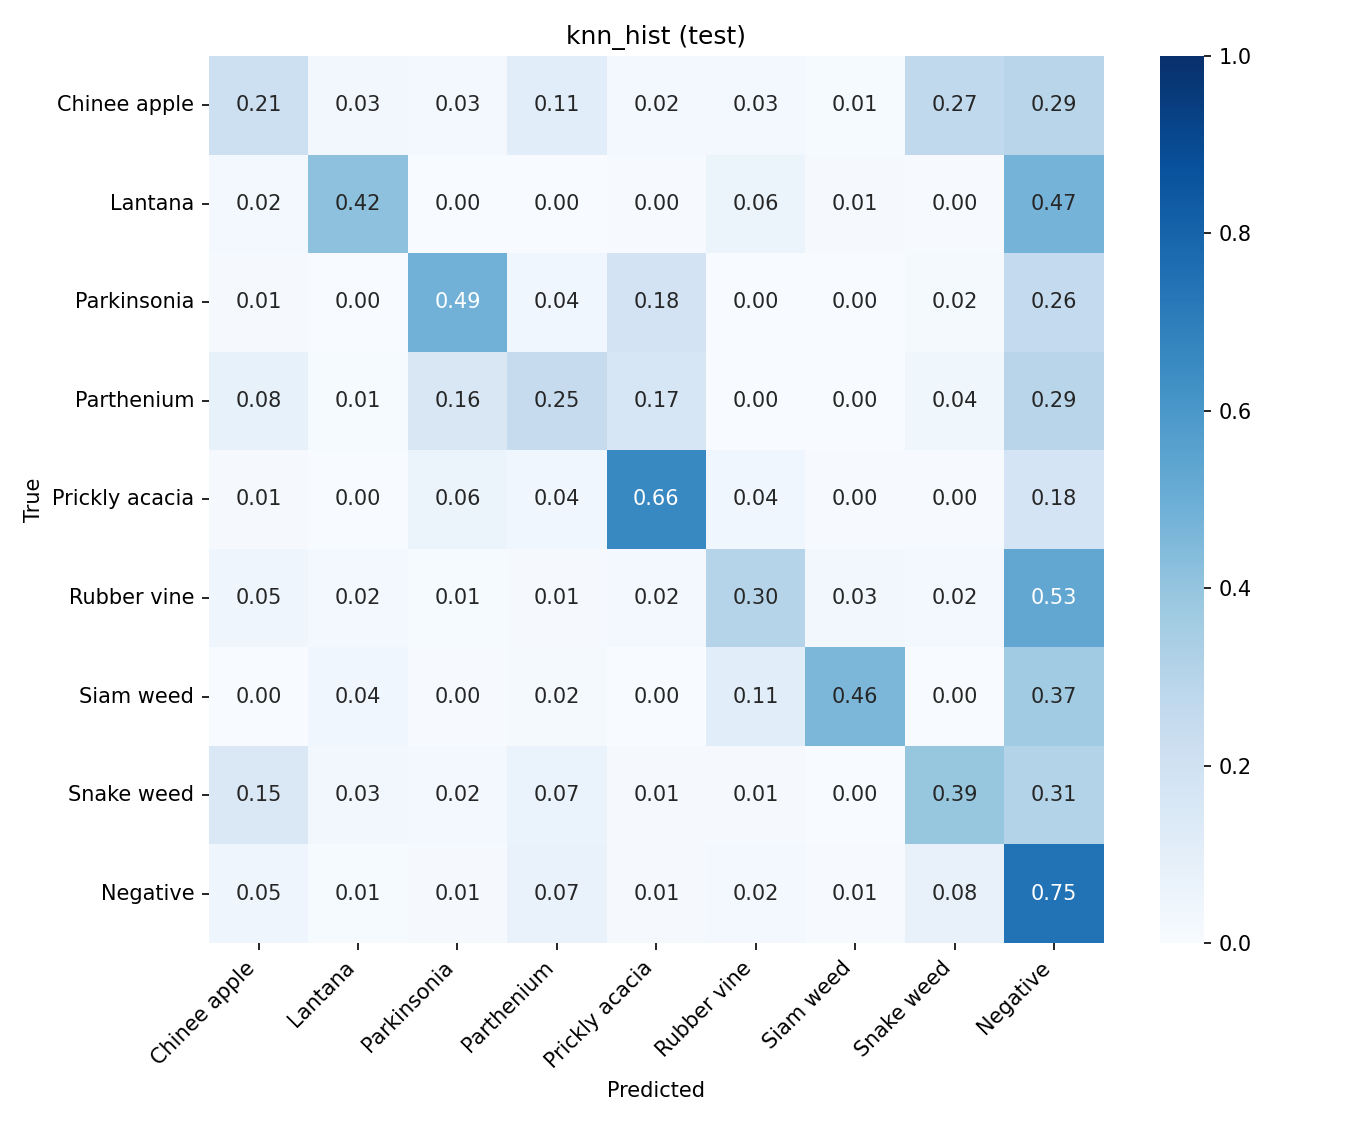

In [5]:
for run in ('knn_pixels', 'knn_hist'):
    display(Image(CM_DIR / f'{run}_test.png', width=600))

In [6]:
for name, r in runs.items():
    print(name)
    for t, p, n in r['top_confusions_test']:
        print(f'  {t} -> {p}: {n}')

KNN pixels
  Negative -> Parkinsonia: 264
  Siam weed -> Negative: 166
  Lantana -> Negative: 137
  Rubber vine -> Negative: 116
  Parkinsonia -> Negative: 74
KNN colour histogram
  Negative -> Snake weed: 142
  Negative -> Parthenium: 129
  Rubber vine -> Negative: 107
  Lantana -> Negative: 101
  Negative -> Chinee apple: 83


## Takeaways

- **Raw pixels barely beat guessing.** Test macro F1 is 0.180 against 0.076 for the majority class, and Rubber vine scores F1 0.02. Distance between pixel vectors measures scene layout and brightness, not the plant. The biggest error is 264 *Negative* images predicted as Parkinsonia.
- **Colour histograms are 2.5× better** (test macro F1 0.452). A histogram ignores *where* things are in the frame, so it is robust to the plant's position. But class colours overlap heavily (notebook 01, section 5), so most errors are between weeds and *Negative*, in both directions: *Negative* → Snake weed 142, *Negative* → Parthenium 129, Rubber vine → *Negative* 107.
- **Features matter far more than tuning.** Across every k, the histogram KNN's validation macro F1 stays between 0.37 and 0.41, and the pixel KNN's between 0.16 and 0.18.
- **Accuracy hides how weak these are.** The histogram KNN's test accuracy (0.581) is only 0.06 above always predicting *Negative* (0.525), which is why macro F1 is the headline metric.

**Answer to Q1:** KNN on HSV colour histograms is the classical baseline to beat, at test macro F1 0.452.